# Aprendizagem Supervisionada 

Trabalho realizado por:
- Francisco Lopes nº111358
- Raul Azevedo nº111479

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

## Exercício 1 - Perceptrão

### Alínea 1 - Criação do Conjunto de Dados 

São criados dois vetores:

- `X`: vetor que guarda todas as combinações possiveis de duas entradas;

- `d`: vetor que guarda as saídas desejadas da operação OR.

In [2]:
X = np.array([[0,0], [0, 1], [1, 0], [1, 1]])

d = np.array([0, 1, 1, 1])


### Alínea 2 - Inicialização dos Pesos e Calculo dos Outputs 

A função `init_weights` inicializa os pesos w0, w1 e w2 com valores aleatórios no intervalo [-0.5, 0.5[.

A função `activation_function` recebe a soma ponderada s = w0 + w1.x1 + w2.x2 calculada para cada entrada. Esta devolve:

- 1 se `s` for maior que 0.5;
- 0 se `s` for menor ou igual a 0.5.

A função `compute_outputs` calcula `s` para cada entrada de `X` e aplica a `activation_function`. Esta devolve o vetor `o` que contem os outputs do perceptrão.

In [3]:

def init_weights(rng=None):
    if rng is None:
        rng = np.random.default_rng()

    return rng.uniform(-0.5, 0.5, 3)


def activation_function(s):
    return 1 if s > 0.5 else 0 


def compute_outputs(X, w):
    o = np.zeros(len(X), dtype=int)
    for i, (x1, x2) in enumerate(X):
        s = w[0] + w[1] * x1 + w[2] * x2
        o[i] = activation_function(s)

    return o

### Alínea 3 - Cálculo do Erro 

A função `compute_error` devolve para cada entrada (x1, x2), a diferença entre a resposta desejada/target `d` e o output do modelo `o`.

O resultado pode ter 3 valores possíveis:
-  0: indica que o output está correto.
-  1: indica que o output é 0, mas a resposta desejada seria 1;
- -1: indica que o output é 1, mas a resposta desejada seria 0.


In [4]:
def compute_error(d, o):
    return d - o


### Alínea 4 - Atualização dos Pesos

A função `compute_deltas` devolve as atualizações acumuladas dos seus respetivos pesos através da Delta Rule. Os pesos não são alterados nesta função.

In [5]:
def compute_deltas(X, e, alpha):
    dw = np.zeros(3)
    for i, (x1, x2) in enumerate(X):
        dw[0] += alpha * e[i]
        dw[1] += alpha * e[i] * x1
        dw[2] += alpha * e[i] * x2

    return dw
          

### Alínea 5 e 6 - Atualização de Pesos por Epoch

A função `train_perceptron`, começa por inicializar os pesos com `init_weights` e em cada epoch:
1. calcula os outputs (`compute_outputs`);
2. calcula o erro (`compute_error`);
3. acumula as atualizações (`compute_deltas`);
4. atualiza os pesos `w += dw`.

No final de cada epoch, guarda o erro total (número de exemplos errados) em `error_history` e os pesos em `weights_history`.


In [6]:
def train_perceptron(X, d, alpha=10E-4, epochs=20, rng=None):
    w = init_weights(rng) 

    error_history = []
    weights_history = []

    for epoch in range(epochs):
        o = compute_outputs(X, w)
        e = compute_error(d, o)
        dw = compute_deltas(X, e, alpha)
        w += dw

        e_new = compute_error(d, compute_outputs(X, w))
        error_history.append(np.sum(np.abs(e_new)))
        weights_history.append(w.copy())

    return np.array(weights_history), np.array(error_history)

#### 6(a) - Representar graficamente o erro no final de cada epoch

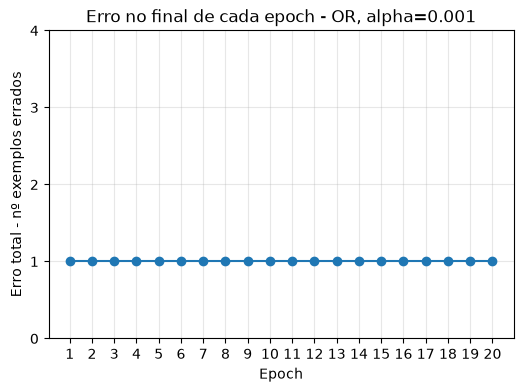

(np.int64(0), np.int64(0)) s = 0.294 | d = 0 | o = 0
(np.int64(0), np.int64(1)) s = 0.6526 | d = 1 | o = 1
(np.int64(1), np.int64(0)) s = 0.2528 | d = 1 | o = 0
(np.int64(1), np.int64(1)) s = 0.6114 | d = 1 | o = 1


In [7]:
rng = np.random.default_rng(42)

weights_history, error_history = train_perceptron(X, d, rng=rng)

epochs_axis = np.arange(1, len(error_history) + 1)

plt.figure(figsize=(6,4))
plt.plot(epochs_axis, error_history, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Erro total - nº exemplos errados")
plt.title("Erro no final de cada epoch - OR, alpha=0.001")
plt.xticks(epochs_axis)
plt.yticks(range(5))
plt.grid(True, alpha=0.3)
plt.show()


w = weights_history[-1]  # pesos finais 
for (x1, x2), target in zip(X, d):
    s = w[0] + w[1] * x1 + w[2] * x2
    print((x1, x2), "s =", round(s, 4), "| d =", target, "| o =", activation_function(s))

**Observações:**

O gráfico demonstra o erro total (número de exemplos errados) no final de cada epoch. O erro mantem-se constante em 1 durante 20 epochs, ou seja, o perceptrão continua a classificar mal uma das entradas, não chegando a aprender a função OR.

Este comportamento pode ser explicado com o valor reduzido de alpha: em cada epoch, os pesos variam apenas com uma taxa de aprendizagem de 0.001. A entrada (1,0) tem target 1 mas `s`<=0.5, e `s` aumenta demasiado devagar para ultrapassar 0.5 e ter 1 como output em 20 épocas.

#### 6(b) - Representar graficamente os pesos no final de cada epoch

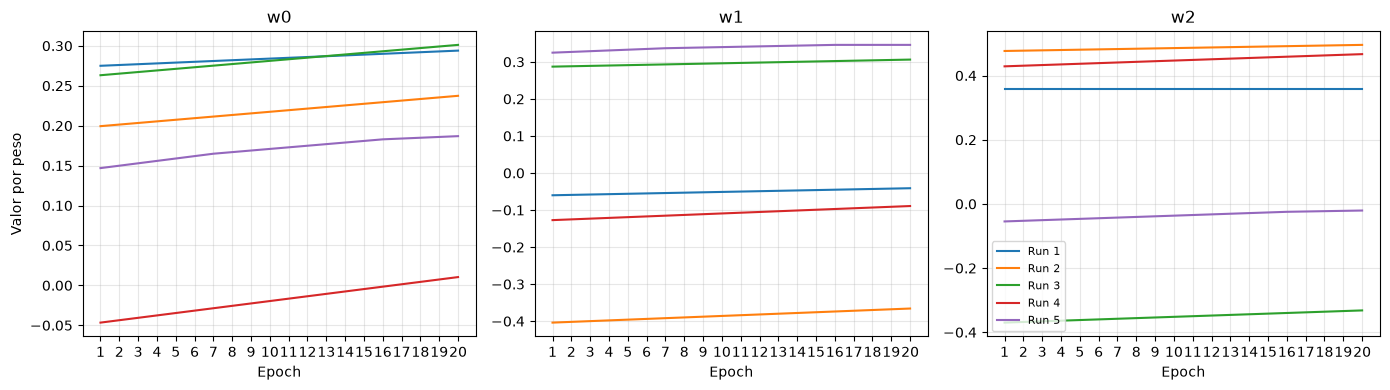

Pesos finais em cada run:
[[ 0.294  -0.0411  0.3586]
 [ 0.2374 -0.3658  0.4956]
 [ 0.3011  0.3061 -0.3319]
 [ 0.0104 -0.0892  0.4668]
 [ 0.1869  0.3458 -0.0206]]


In [8]:
n_runs = 5
fig, axes = plt.subplots(1, 3, figsize=(14,4), sharex=True)
names = ["w0", "w1", "w2"]

final_weights = []
rng = np.random.default_rng(42)
for run in range(n_runs):
    w_hist, _ = train_perceptron(X, d, rng=rng)
    final_weights.append(w_hist[-1])
    for k in range(3):
        axes[k].plot(epochs_axis, w_hist[:, k], label=f"Run {run +1}")

for k in range(3):
    axes[k].set_title(names[k])
    axes[k].set_xlabel("Epoch")
    axes[k].set_xticks(epochs_axis)
    axes[k].grid(True, alpha=0.3)

axes[0].set_ylabel("Valor por peso")
axes[2].legend(fontsize=8)
plt.tight_layout()
plt.show()

print("Pesos finais em cada run:")
print(np.array(final_weights).round(4))

Os gráficos demonstram a evolução de `w0`, `w1`e `w2` ao longo de 20 epochs e com uma taxa de aprendizagem de 0.001, em cinco diferentes inicializações aleatórias de pesos.

**Observações:**
- Os pesos variam de forma lenta e linear, sem haver estabilização evidente;
- Os valores finais dos pesos diferem entre as runs;
- As variações dos pesos por epoch são muito menores face às suas variações em cada run, o que demonstra que o resultado dependeu dos seus valores iniciais.

#### 6(c) - Efeito de alpha 

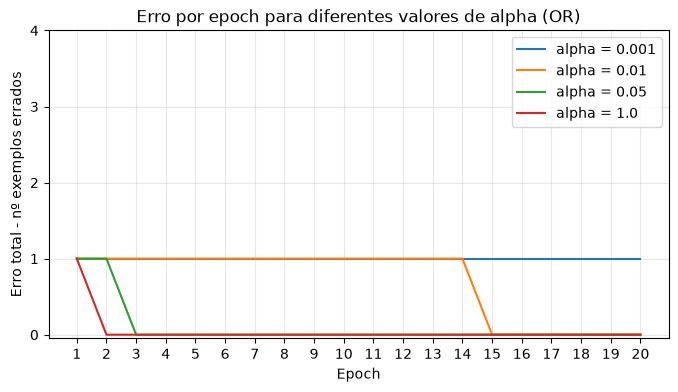

In [9]:
alphas = [10E-4, 10E-3, 0.05, 10E-1]
epochs = 20
epochs_axis = np.arange(1, epochs + 1)

plt.figure(figsize=(8, 4))
for alpha in alphas:
    rng = np.random.default_rng(42)
    _, error_history = train_perceptron(X, d, alpha=alpha, epochs=epochs, rng=rng)
    plt.plot(epochs_axis, error_history, label=f"alpha = {alpha}")

plt.xlabel("Epoch")
plt.ylabel("Erro total - nº exemplos errados")
plt.title("Erro por epoch para diferentes valores de alpha (OR)")
plt.xticks(epochs_axis)
plt.yticks(range(5))
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

O gráfico compara o erro por epoch para 4 valores de alpha (0.001, 0.01, 0.05, 1.0), com 20 epochs e os mesmos pesos iniciais.

**Resultados:**

| Alpha | Epoch em que o erro chega a 0 |
|---|---|
| 0.001 | Não converge em 20 epochs |
| 0.01 | 15 |
| 0.05 | 3 |
| 1.0 | 2 |

**Observações:**
- Aumentar alpha acelera a convergência, visto que os pesos são atualizados com uma maior taxa de aprendizagem
- Dos alphas testados, o melhor foi o alpha 1.0


#### 6(d) - Número de epochs até convergir 

In [10]:
n_runs = 30
max_epochs = 1000
alpha = 10E-4

rng = np.random.default_rng(42)
epochs_needed = []

for run in range(n_runs):
     _, error_history = train_perceptron(X, d, alpha=alpha, epochs=max_epochs, rng=rng)
     zeros = np.where(error_history == 0)[0]
     epochs_needed.append(zeros[0] + 1 if len(zeros) > 0 else np.nan)

epochs_needed = np.array(epochs_needed)

print("Nº Epochs para convergir:", epochs_needed)
print(f"Média = {np.nanmean(epochs_needed):.2f} | Desvio padrão = {np.nanstd(epochs_needed):.2f}")
print("Runs que não convergiram:", np.isnan(epochs_needed).sum())

Nº Epochs para convergir: [144 362 310 286 187 359  21  97 223 412 215 263 312 184 212 147 279 244
 157 262 107  70 316 223 438 297 113 335 446 253]
Média = 242.47 | Desvio padrão = 105.97
Runs que não convergiram: 0


O treino foi repetido 30 vezes, com pesos iniciais diferentes, alpha = 0.001 e um máximo de epochs igual a 1000 para cada execução. A convergência corresponde ao primeiro epoch em que todos os exemplos são classificados corretamente.

**Resultados:**

| Métrica | Valor |
|---|---|
| Média de epochs | 242.47 |
| Desvio padrão | 105.97 |
| Mínimo / Máximo | 21 / 446 |
| Runs que não convergiram | 0 |

**Observações:**
- As 30 execuções obtiveram todos os exemplos corretos antes do limite (1000 epochs);
- Os valores variam bastante entre execuções (21 a 446 épocas), o que mostra que o número de epochs, para além de alpha, depende dos pesos iniciais.

### Alínea 7 - Geração de uma Distribuição Gaussiana Multivariada

São gerados dois sets de 500 pontos 2D com distribuições gaussianas multivariadas:

- **Set A**: média (3,3), covariância [[1, 0], [0, 1]]
- **Set B**: média (-3,-3), covariância [[2, 0], [0, 5]]

**Labels:** É acrescentada uma terceira coluna com a origem de cada ponto: 0 para o set A e 1 para o set B;

**Preparação:** Os dois sets foram concatenados numa matriz 1000 x 3 e baralhados.

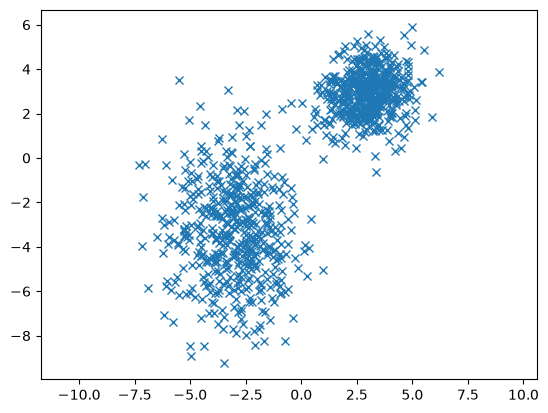

In [11]:
rng = np.random.default_rng(42)

mean_a = [3, 3]
cov_a = [[1, 0], [0, 1]]
a = rng.multivariate_normal(mean_a, cov_a, 500)  # 500 x 2

mean_b = [-3, -3]
cov_b = [[2, 0], [0, 5]]
b = rng.multivariate_normal(mean_b, cov_b, 500) # 500 x 2

labels_a = np.zeros(500)
labels_b = np.ones(500)

a = np.column_stack((a, labels_a)) # 500 x 3
b = np.column_stack((b, labels_b)) # 500 x 3

dataset = np.concatenate((a, b), axis=0) # 1000 x 3
rng.shuffle(dataset)

x = dataset[:, 0]
y = dataset[:, 1]

plt.plot(x, y, 'x')
plt.axis('equal')
plt.show()

np.savetxt("gaussian_dataset.csv", dataset, delimiter=",", header="x1,x2,label", comments="", fmt=['%.5f', '%.5f', '%d'])
           


### Alínea 8

É realizada a separação dos dados de treino e de teste.

O dataset, já baralhado, é dividido em dois conjuntos:
- **Treino (70%):** 700 pontos, usados para treinar o perceptrão;
- **Teste (30%):** 300 pontos, reservados para a avaliação.

As duas primeiras colunas são as coordenadas dos pontos e a terceira coluna é a respetiva label(0 para a 1.ª distribuição e 1 para a 2.ª).

In [12]:
X_all = dataset[:, :2]
y_all = dataset[:, 2].astype(int) # labels 

training_set = int(0.7 * len(dataset)) # 700 pontos 

X_train, y_train = X_all[:training_set], y_all[:training_set]
X_test, y_test = X_all[training_set:], y_all[training_set:]

**Treino do Perceptrão** com alpha = 0.001 e 100 epochs 

In [13]:
alpha = 10E-4
epochs = 100

rng = np.random.default_rng(42)
weights_history, error_history = train_perceptron(X_train, y_train, alpha=alpha, epochs=epochs, rng=rng)
w = weights_history[-1]

print("Pesos finais:", w.round(4))
print("Erro final - nº de pontos errados:", error_history[-1])

Pesos finais: [ 0.501  -2.1357 -1.5382]
Erro final - nº de pontos errados: 2


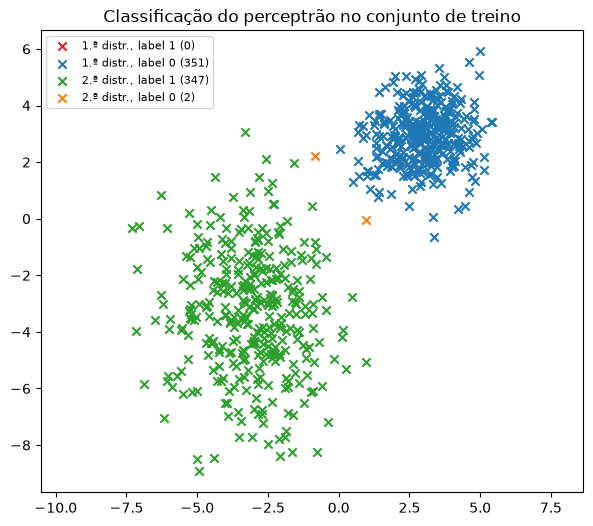

In [14]:
o_train = compute_outputs(X_train, w)

a_1 = (y_train == 0) & (o_train == 1)   # (a) 1.ª distribuição, previsto 1 - errado
a_0 = (y_train == 0) & (o_train == 0)   # (b) 1.ª distribuição, previsto 0 - correto
b_1 = (y_train == 1) & (o_train == 1)   # (c) 2.ª distribuição, previsto 1 - correto
b_0 = (y_train == 1) & (o_train == 0)   # (d) 2.ª distribuição, previsto 0 - errado

plt.figure(figsize=(7, 6))
plt.scatter(*X_train[a_1].T, c="tab:red",    marker="x", label=f"1.ª distr., label 1 ({a_1.sum()})")
plt.scatter(*X_train[a_0].T, c="tab:blue",   marker="x", label=f"1.ª distr., label 0 ({a_0.sum()})")
plt.scatter(*X_train[b_1].T, c="tab:green",  marker="x", label=f"2.ª distr., label 1 ({b_1.sum()})")
plt.scatter(*X_train[b_0].T, c="tab:orange", marker="x", label=f"2.ª distr., label 0 ({b_0.sum()})")
plt.axis("equal")
plt.legend(fontsize=8)
plt.title("Classificação do perceptrão no conjunto de treino")
plt.show()

O gráfico apresenta os pontos de treino em quatro grupos, consoante a distribuição de origem e a previsão do perceptrão.

**Resultados:**
| Cor | Origem | Previsão | Resultado | Pontos |
|---|---|---|---|---|
| Vermelho | 1.ª distribuição | 1 | errado | 0 |
| Azul | 1.ª distribuição | 0 | correto | 351 |
| Verde | 2.ª distribuição | 1 | correto | 347 |
| Laranja | 2.ª distribuição | 0 | errado | 2 |

Dos 700 pontos, 698 são bem classificados (99.7%) e apenas 2 são classificados incorretamente.

### Alínea 9 - Matriz de Confusão

A função `compute_confusion_matrix` compara as labels reais (`y_true`) com as previsões do perceptrão (`y_pred`):
- `tn` (verdadeiros negativos): real 0 e previsto 0;
- `fp` (falsos positivos): real 0 e previsto 1;
- `fn` (falsos negativos): real 1 e previsto 0;
- `tp` (verdadeiros positivos): real 1 e previsto 1.

Devolve a matriz 2 × 2 `[[tn, fp], [fn, tp]]`, em que as linhas representam o valor real e as colunas a previsão.

In [15]:
def compute_confusion_matrix(y_true, y_pred):
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    tp = np.sum((y_true == 1) & (y_pred == 1))
    return np.array([[tn, fp], [fn, tp]])

cm = compute_confusion_matrix(y_train, o_train)
print("Matriz de confusão (treino):")
print(cm)
                     

Matriz de confusão (treino):
[[351   0]
 [  2 347]]


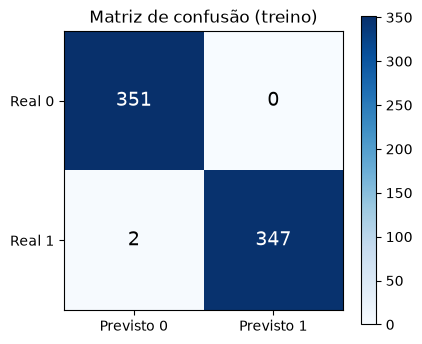

In [16]:
plt.figure(figsize=(4.5, 4))
plt.imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center", fontsize=14,
                 color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.xticks([0, 1], ["Previsto 0", "Previsto 1"])
plt.yticks([0, 1], ["Real 0", "Real 1"])
plt.title("Matriz de confusão (treino)")
plt.colorbar()
plt.show()

A matriz de confusão do conjunto de treino é:

|  | Previsto 0 | Previsto 1 |
|---|---|---|
| **Real 0** | 351 (TN) | 0 (FP) |
| **Real 1** | 2 (FN) | 347 (TP) |

### Alínea 10 - 30 runs sobre o conjunto de teste

In [17]:
def compute_metrics(cm):
    tn, fp = cm[0]
    fn, tp = cm[1]

    accuracy  = (tp + tn) / (tp + tn + fp + fn)
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall    = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0.0

    return accuracy, precision, recall, f1

O perceptrão é treinado 30 vezes com o conjunto de treino (70%), usando os mesmos parâmetros (alpha = 0.001, 100 epochs) e pesos iniciais diferentes em cada treino. Cada modelo é avaliado no conjunto de teste (30%, 300 pontos), que se mantém fixo. Em cada run calculam-se a matriz de confusão e as métricas, e no final obtêm-se as médias e os desvios padrão.

In [18]:
n_runs = 30
alpha = 10E-4
epochs = 100

rng = np.random.default_rng(42)     

cms = []
metrics = []

for run in range(n_runs):
    weights_history, _ = train_perceptron(X_train, y_train, alpha=alpha, epochs=epochs, rng=rng)
    w = weights_history[-1] 

    o_test = compute_outputs(X_test, w)
    cm = compute_confusion_matrix(y_test, o_test)

    cms.append(cm)
    metrics.append(compute_metrics(cm))

cms = np.array(cms)  # 30 x 2 x 2
metrics = np.array(metrics) # 30 x 4

cm_mean = cms.mean(axis=0)
metrics_mean = metrics.mean(axis=0)
metrics_std = metrics.std(axis=0)

print("Matriz de confusão média (teste):")
print(cm_mean.round(2))

print()
for name, m, s in zip(["Accuracy", "Precision", "Recall", "F1"], metrics_mean, metrics_std):
    print(f"{name:<10} média = {m:.4f} | desvio padrão = {s:.4f}")

Matriz de confusão média (teste):
[[149.   0.]
 [  3. 148.]]

Accuracy   média = 0.9900 | desvio padrão = 0.0000
Precision  média = 1.0000 | desvio padrão = 0.0000
Recall     média = 0.9801 | desvio padrão = 0.0000
F1         média = 0.9900 | desvio padrão = 0.0000


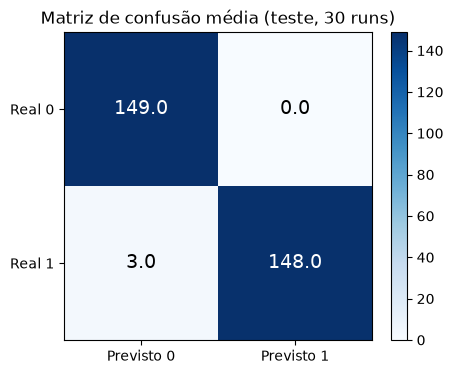

In [19]:
plt.figure(figsize=(5, 4))
plt.imshow(cm_mean, cmap="Blues")
for i in range(2):
    for j in range(2):
        plt.text(j, i, f"{cm_mean[i, j]:.1f}", ha="center", va="center", fontsize=14,
                 color="white" if cm_mean[i, j] > cm_mean.max() / 2 else "black")
plt.xticks([0, 1], ["Previsto 0", "Previsto 1"])
plt.yticks([0, 1], ["Real 0", "Real 1"])
plt.title("Matriz de confusão média (teste, 30 runs)")
plt.colorbar()
plt.show()

A matriz de confusão média é:

|  | Previsto 0 | Previsto 1 |
|---|---|---|
| **Real 0** | 149 (TN) | 0 (FP) |
| **Real 1** | 3 (FN) | 148 (TP) |

As métricas médias das 30 runs são:

| Métrica | Média | Desvio padrão |
|---|---|---|
| Accuracy | 0.9900 | 0.0000 |
| Precision | 1.0000 | 0.0000 |
| Recall | 0.9801 | 0.0000 |
| F1 | 0.9900 | 0.0000 |

**Observações:**
- Os resultados no teste (accuracy de 99%) são consistentes com os do treino (698 em 700 pontos corretos, 99.7%);
- O desvio padrão é nulo porque a matriz de confusão é idêntica nas 30 corridas (`[149, 0, 3, 148]`). Os pesos finais diferem entre corridas, mas as retas de separação resultantes produzem o mesmo número de acertos e erros.

## Exercício 2 - k-NN

### Alínea 1

In [20]:
from ucimlrepo import fetch_ucirepo

#### Tratamento dos Dados

- `X`: matriz 150 × 4 com as variáveis de cada flor (comprimento e largura da sépala, comprimento e largura da pétala, em cm);
- `y_raw`: nomes das classes (`Iris-setosa`, `Iris-versicolor` e `Iris-virginica`);
- **`class_names`:** as três classes distintas, por ordem alfabética;
- **`y`:** classes convertidas em inteiros (0, 1 e 2), correspondentes à posição em `class_names`, o que simplifica a contagem de votos e a construção da matriz de confusão.

In [21]:
iris = fetch_ucirepo(id=53)

X = iris.data.features.to_numpy() # 150 x 4
y_raw = iris.data.targets["class"].to_numpy() # nomes das classes

class_names = np.unique(y_raw) # Iris-setosa, Iris-versicolor, Iris-virginica
y = np.searchsorted(class_names, y_raw)

print(X.shape, class_names, np.bincount(y))


(150, 4) ['Iris-setosa' 'Iris-versicolor' 'Iris-virginica'] [50 50 50]


#### Algoritmo k-NN

A função `knn_predict` classifica um exemplo `x` através dos seguintes passos:
1. calcula a distância euclidiana de `x` a todos os exemplos de treino;
2. seleciona os `k` exemplos de treino mais próximos;
3. conta os votos de cada classe entre esses `k` vizinhos;
4. devolve a classe com mais votos - em caso de empate `np.argmax` devolve a classe com menor índice.

A função `knn_predict_all` aplica a função `knn_predict` para todos os exemplos do conjunto de treino, devolvendo um array com todas as previsões.

In [22]:
def knn_predict(X_train, y_train, x, k):
    distances = np.sqrt(np.sum((X_train - x) ** 2, axis =1))
    nearest = np.argsort(distances)[:k] # indices dos k mais próximos 
    votes = np.bincount(y_train[nearest], minlength=3)
    return np.argmax(votes)

def knn_predict_all(X_train, y_train, X_test, k):
    return np.array([knn_predict(X_train, y_train, x, k) for x in X_test])


#### Divisão dos Dados

A função `split_set` divide aleatoriamente o dataset num conjunto de treino (70% do dataset) e num conjunto de teste(30% do dataset).

Devolve as features e as labels de treino e de teste.

In [23]:
def split_set(X, y, rng, train=0.7):
    idx = rng.permutation(len(X))
    n_train = int(train * len(X))
    return X[idx[:n_train]], X[idx[n_train:]], y[idx[:n_train]], y[idx[n_train:]]

#### Treino/Teste do k-NN (30 runs)

In [24]:
ks = [3, 7, 11]
n_runs = 30
rng = np.random.default_rng(42)
accuracies = {k: [] for k in ks}

for run in range(n_runs):
    X_train, X_test, y_train, y_test = split_set(X, y, rng)
    for k in ks:
        y_pred = knn_predict_all(X_train, y_train, X_test, k)
        accuracies[k].append(np.mean(y_pred == y_test))

for k in ks:
    print(f"k = {k:<2} | média = {np.mean(accuracies[k]):.4f} | desvio padrão = {np.std(accuracies[k]):.4f}")

k = 3  | média = 0.9570 | desvio padrão = 0.0281
k = 7  | média = 0.9615 | desvio padrão = 0.0292
k = 11 | média = 0.9578 | desvio padrão = 0.0259


O k-NN é testado 30 vezes para diferentes valores de k (3, 7, 11), com diferentes divisões de treino e de teste.

Em cada run, os três valores de `k` são avaliados sobre a mesma divisão, de modo que as diferenças entre eles não dependam da divisão escolhida.

| k | Average Accuracy | Desvio padrão |
|---|---|---|
| 3 | 0.9570 | 0.0281 |
| 7 | 0.9615 | 0.0292 |
| 11 | 0.9578 | 0.0259 |


**Observações:**
- As três médias situam-se entre 95.7% e 96.2%.
- A diferença entre o melhor valor (`k = 7`) e o pior (`k = 3`) é de cerca de 0.5 pontos percentuais, muito inferior ao desvio padrão (cerca de 3 pontos percentuais). Os três valores de `k` têm, por isso, um desempenho equivalente neste dataset.

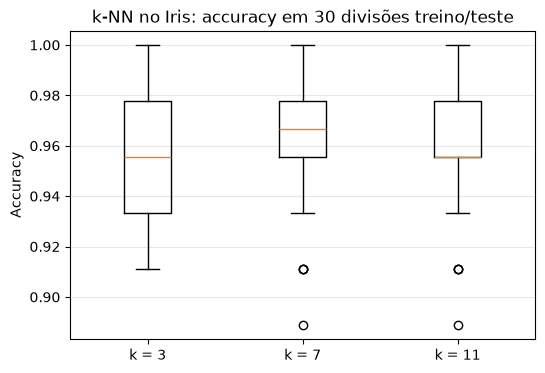

In [25]:
plt.figure(figsize=(6, 4))
plt.boxplot([accuracies[k] for k in ks], whis=1.5)
plt.xticks([1, 2, 3], [f"k = {k}" for k in ks])
plt.ylabel("Accuracy")
plt.title("k-NN no Iris: accuracy em 30 divisões treino/teste")
plt.grid(True, axis="y", alpha=0.3)
plt.show()

O boxplot compara a distribuição da accuracy nas 30 repetições.

**Observações:**
- A caixa mostra o intervalo entre o 1.º e o 3.º quartil, e a linha laranja a mediana (2.º quartil).
- Os bigodes chegam a 1.0 nos três casos, ou seja, há divisões em que todos os exemplos de teste são classificados corretamente.
- Para `k = 7` e `k = 11` aparecem alguns outliers (aproximadamente entre 0.89 a 0.91), correspondentes a divisões menos favoráveis. Para `k = 3` não há valores atípicos, mas a caixa é mais larga para baixo.


### Alínea 2

A função `confusion_matrix_multi` constrói uma matriz de confusão 3 × 3 (uma linha e uma coluna por classe). As linhas representam a classe real e as colunas a classe prevista, pelo que a diagonal contém os acertos.

A função `metrics_multi` calcula as métricas a partir da matriz de confusão.

In [26]:
def confusion_matrix_multi(y_true, y_pred, n_classes=3):
    cm = np.zeros((n_classes, n_classes), dtype=int)
    for t, p in zip(y_true, y_pred):
        cm[t, p] += 1
    return cm

def metrics_multi(cm):
    tp = np.diag(cm)
    fp = cm.sum(axis=0) - tp
    fn = cm.sum(axis=1) - tp

    accuracy = tp.sum() / cm.sum()
    precision = np.divide(tp, tp + fp, out=np.zeros(len(tp)), where=(tp + fp) > 0)
    recall    = np.divide(tp, tp + fn, out=np.zeros(len(tp)), where=(tp + fn) > 0)
    f1 = np.divide(2 * precision * recall, precision + recall, out=np.zeros(len(tp)), where=(precision + recall) > 0)
                   
    return accuracy, precision, recall, f1

k = 3
Accuracy = 1.0000
  setosa      precision = 1.0000 | recall = 1.0000 | F1 = 1.0000
  versicolor  precision = 1.0000 | recall = 1.0000 | F1 = 1.0000
  virginica   precision = 1.0000 | recall = 1.0000 | F1 = 1.0000
  Média       precision = 1.0000 | recall = 1.0000 | F1 = 1.0000

k = 7
Accuracy = 0.9778
  setosa      precision = 1.0000 | recall = 1.0000 | F1 = 1.0000
  versicolor  precision = 0.9091 | recall = 1.0000 | F1 = 0.9524
  virginica   precision = 1.0000 | recall = 0.9375 | F1 = 0.9677
  Média       precision = 0.9697 | recall = 0.9792 | F1 = 0.9734

k = 11
Accuracy = 0.9556
  setosa      precision = 1.0000 | recall = 1.0000 | F1 = 1.0000
  versicolor  precision = 0.8333 | recall = 1.0000 | F1 = 0.9091
  virginica   precision = 1.0000 | recall = 0.8750 | F1 = 0.9333
  Média       precision = 0.9444 | recall = 0.9583 | F1 = 0.9475



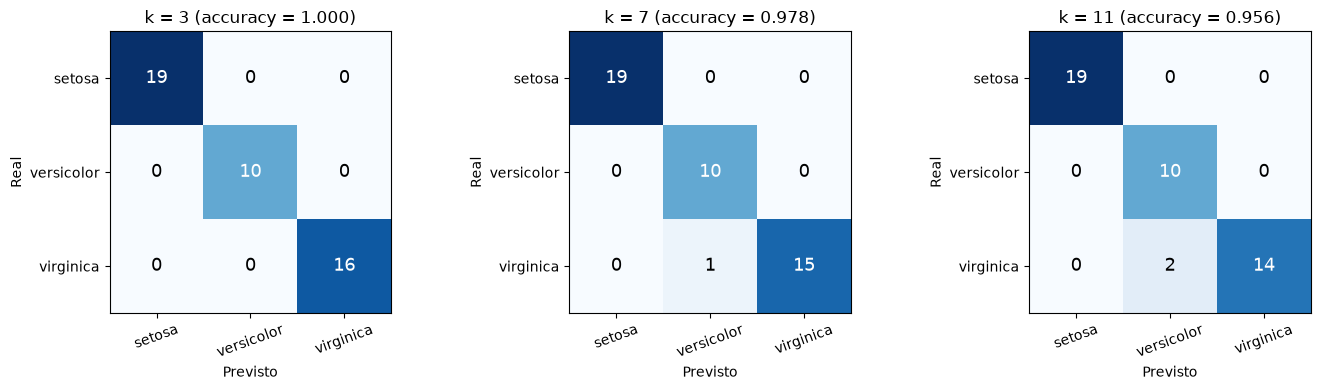

In [27]:
rng = np.random.default_rng(42)
X_train, X_test, y_train, y_test = split_set(X, y, rng)

short_names = [name.replace("Iris-", "") for name in class_names]

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, k in zip(axes, ks):
    y_pred = knn_predict_all(X_train, y_train, X_test, k)
    cm = confusion_matrix_multi(y_test, y_pred)
    accuracy, precision, recall, f1 = metrics_multi(cm)

    print(f"k = {k}")
    print(f"Accuracy = {accuracy:.4f}")
    for i, name in enumerate(short_names):
        print(f"  {name:<11} precision = {precision[i]:.4f} | recall = {recall[i]:.4f} | F1 = {f1[i]:.4f}")
    print(f"  {'Média':<11} precision = {precision.mean():.4f} | recall = {recall.mean():.4f} | F1 = {f1.mean():.4f}\n")

    ax.imshow(cm, cmap="Blues")
    for i in range(3):
        for j in range(3):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=13,
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xticks(range(3), short_names, rotation=20)
    ax.set_yticks(range(3), short_names)
    ax.set_xlabel("Previsto")
    ax.set_ylabel("Real")
    ax.set_title(f"k = {k} (accuracy = {accuracy:.3f})")

plt.tight_layout()
plt.show()

Os resultados apresentados correspondem a uma única divisão treino/teste.Os três valores de `k` são avaliados sobre a mesma divisão.

| k | Accuracy | Precision (média) | Recall (média) | F1 (média) |
|---|---|---|---|---|
| 3 | 1.0000 | 1.0000 | 1.0000 | 1.0000 |
| 7 | 0.9778 | 0.9697 | 0.9792 | 0.9734 |
| 11 | 0.9556 | 0.9444 | 0.9583 | 0.9475 |

**Matrizes de confusão:**
- **k = 3:** todos os 45 exemplos são classificados corretamente (matriz diagonal: 19, 10 e 16).
- **k = 7:** 1 exemplo de virginica é classificado como versicolor.
- **k = 11:** 2 exemplos de virginica são classificados como versicolor.

**Observações:**
- A **setosa** é classificada sem erros em todos os casos (precision, recall e F1 de 1.0), o que é coerente com o facto de ser a classe mais separada das outras duas.
- Os erros ocorrem apenas entre **versicolor** e **virginica**, sempre no mesmo sentido: exemplos de virginica previstos como versicolor. 
- Neste teste, a accuracy desce à medida que `k` aumenta. 

Nota: Este resultado dependeu da divisão escolhida. Nas 30 repetições do ponto anterior, `k = 3` teve a média de accuracy mais baixa (0.9570) e `k = 7` a mais alta (0.9615), pelo que a ordem observada aqui não se mantém em média. Um único teste serve para ilustrar a matriz de confusão e as métricas, e não para escolher o melhor `k`.

### Alínea 3 

No dataset da Figura 3 existem duas classes correspondentes às duas distribuições. O k-NN classifica por maioria os `k` vizinhos mais próximos, e com `k` ímpar um dos lados tem sempre mais votos, pelo que nunca há empate.

Com `k` par, os vizinhos podem dividir-se em partes iguais (por exemplo, 2/2 com `k = 4`), e a decisão passa a depender de uma regra de desempate arbitrária.



## Exercício 3 - Naive Bayes classifier

#### 1- Transform by discretizing all columns’ values into categories with three possible values (low/medium/high). 

Use a sensible partition for each column. As in the previous exercise, split the dataset randomly in two subsets (70%/30%). Repeat the process of the previous exercise to obtain evaluation metrics and an example of a confusion matrix (this time, there is no parameter to vary, soonly one cycle of 30 repetitions with different dataset partitions).

In [28]:
# Exercício 3 - Naive Bayes com atributos discretizados

if "iris" not in globals():
    from ucimlrepo import fetch_ucirepo
    iris = fetch_ucirepo(id=53)

X_iris_raw = iris.data.features.to_numpy()
y_iris = iris.data.targets["class"].to_numpy()
class_names_nb = np.unique(y_iris)
feature_names = ["sepal_length", "sepal_width", "petal_length", "petal_width"]


def discretize_with_thresholds(values, thresholds):
    discretized_values = np.zeros_like(values, dtype=int)
    for feature_index in range(values.shape[1]):
        discretized_values[:, feature_index] = np.digitize(
            values[:, feature_index], thresholds[:, feature_index]
        )
    return discretized_values


def naive_bayes_fit(X_train, y_train, classes, n_categories=3):
    class_count = len(classes)
    priors = np.zeros(class_count, dtype=float)
    conditional_probabilities = np.zeros(
        (class_count, X_train.shape[1], n_categories), dtype=float
    )

    for class_index, class_name in enumerate(classes):
        class_rows = X_train[y_train == class_name]
        priors[class_index] = (len(class_rows) + 1) / (
            len(X_train) + class_count
        )

        for feature_index in range(X_train.shape[1]):
            for category in range(n_categories):
                category_count = np.sum(class_rows[:, feature_index] == category)
                conditional_probabilities[class_index, feature_index, category] = (
                    category_count + 1
                ) / (len(class_rows) + n_categories)

    return priors, conditional_probabilities


def naive_bayes_predict(X_test, priors, conditional_probabilities, classes):
    predictions = []
    for example in X_test:
        class_scores = []
        for class_index, prior in enumerate(priors):
            score = np.log(prior)
            for feature_index, category in enumerate(example):
                score += np.log(
                    conditional_probabilities[class_index, feature_index, category]
                )
            class_scores.append(score)
        predictions.append(classes[np.argmax(class_scores)])
    return np.array(predictions)


def confusion_matrix_nb(y_true, y_pred, classes):
    matrix = np.zeros((len(classes), len(classes)), dtype=int)
    for true_class, predicted_class in zip(y_true, y_pred):
        true_index = np.where(classes == true_class)[0][0]
        predicted_index = np.where(classes == predicted_class)[0][0]
        matrix[true_index, predicted_index] += 1
    return matrix


def metrics_from_multiclass_matrix(matrix):
    true_positives = np.diag(matrix).astype(float)
    false_positives = matrix.sum(axis=0) - true_positives
    false_negatives = matrix.sum(axis=1) - true_positives

    accuracy = true_positives.sum() / matrix.sum()
    precision = np.divide(
        true_positives,
        true_positives + false_positives,
        out=np.zeros_like(true_positives),
        where=(true_positives + false_positives) > 0,
    )
    recall = np.divide(
        true_positives,
        true_positives + false_negatives,
        out=np.zeros_like(true_positives),
        where=(true_positives + false_negatives) > 0,
    )
    f1 = np.divide(
        2 * precision * recall,
        precision + recall,
        out=np.zeros_like(precision),
        where=(precision + recall) > 0,
    )

    return accuracy, precision, recall, f1


n_nb_runs = 30
nb_rng = np.random.default_rng(42)
nb_confusion_matrices = []
nb_metrics = []

for run_index in range(n_nb_runs):
    shuffled_indices = nb_rng.permutation(len(X_iris_raw))
    n_nb_train = int(0.7 * len(X_iris_raw))
    train_indices = shuffled_indices[:n_nb_train]
    test_indices = shuffled_indices[n_nb_train:]

    X_nb_train_raw = X_iris_raw[train_indices]
    X_nb_test_raw = X_iris_raw[test_indices]
    y_nb_train = y_iris[train_indices]
    y_nb_test = y_iris[test_indices]

    # Os limiares usam apenas o treino; o teste não influencia a discretização.
    nb_thresholds = np.quantile(X_nb_train_raw, [1 / 3, 2 / 3], axis=0)
    X_nb_train = discretize_with_thresholds(X_nb_train_raw, nb_thresholds)
    X_nb_test = discretize_with_thresholds(X_nb_test_raw, nb_thresholds)

    nb_priors, nb_conditionals = naive_bayes_fit(
        X_nb_train, y_nb_train, class_names_nb
    )
    nb_predictions = naive_bayes_predict(
        X_nb_test, nb_priors, nb_conditionals, class_names_nb
    )
    nb_matrix = confusion_matrix_nb(y_nb_test, nb_predictions, class_names_nb)
    accuracy, precision, recall, f1 = metrics_from_multiclass_matrix(nb_matrix)

    nb_confusion_matrices.append(nb_matrix)
    nb_metrics.append(
        [accuracy, precision.mean(), recall.mean(), f1.mean()]
    )

nb_confusion_mean = np.mean(nb_confusion_matrices, axis=0)
nb_metrics = np.array(nb_metrics)
nb_metrics_mean = nb_metrics.mean(axis=0)
nb_metrics_std = nb_metrics.std(axis=0)

print("Matriz de confusão média (30 runs):")
print(nb_confusion_mean.round(2))
print("\nMétricas médias e desvios padrão:")
for metric_name, mean_value, std_value in zip(
    ["Accuracy", "Precision", "Recall", "F1"], nb_metrics_mean, nb_metrics_std
):
    print(f"{metric_name:<10} média = {mean_value:.4f} | desvio padrão = {std_value:.4f}")

Matriz de confusão média (30 runs):
[[14.7   0.03  0.  ]
 [ 0.07 12.97  1.63]
 [ 0.    1.47 14.13]]

Métricas médias e desvios padrão:
Accuracy   média = 0.9289 | desvio padrão = 0.0360
Precision  média = 0.9327 | desvio padrão = 0.0327
Recall     média = 0.9266 | desvio padrão = 0.0366
F1         média = 0.9271 | desvio padrão = 0.0357


Em cada uma das 30 repetições, os dados foram divididos em treino (70%) e teste (30%). Os limiares dos tercis foram calculados apenas com os dados de treino e depois aplicados tanto ao treino como ao teste. Desta forma, o conjunto de teste não influencia a discretização.

Foram usadas suavização de Laplace e probabilidades em logaritmo. A suavização evita probabilidades nulas quando uma categoria não aparece numa classe do conjunto de treino.

A matriz de confusão média nas 30 divisões foi:

| Real / Previsto | setosa | versicolor | virginica |
|---|---:|---:|---:|
| **setosa** | 14.70 | 0.03 | 0.00 |
| **versicolor** | 0.07 | 12.97 | 1.63 |
| **virginica** | 0.00 | 1.47 | 14.13 |

<br>

| Métrica | Média | Desvio padrão |
|---|---:|---:|
| Accuracy | 0.9289 | 0.0360 |
| Precision macro | 0.9327 | 0.0327 |
| Recall macro | 0.9266 | 0.0366 |
| F1 macro | 0.9271 | 0.0357 |

A classe setosa continua a ser a mais fácil de classificar. Os erros concentram-se sobretudo entre versicolor e virginica, que são as classes mais próximas no dataset Iris.

#### 2- How does this classifier compare to the *k*-NN classifier?

Remember that the probability of an event/example belonging to a given class \( P(\text{Class} \mid X) \) is calculated by:

$$
P(\text{Class} \mid X)
=
\frac{P(X \mid \text{Class}) \, P(\text{Class})}{P(X)}
$$

and the decision between classes for a given example \( X \) is made by comparing the values for each class of:

$$
P(X \mid \text{Class}) \, P(\text{Class})
$$

which is approximated (using the independence assumption) by:

$$
P(\text{Class})
\prod_i P(X_i \mid \text{Class})
$$

In [29]:
# Comparação com os resultados do k-NN do Exercício 2

knn_summary = []
for k_value in ks:
    knn_summary.append([
        k_value,
        np.mean(accuracies[k_value]),
        np.std(accuracies[k_value]),
    ])

comparison_table = pd.DataFrame(
    knn_summary,
    columns=["k", "accuracy_media", "accuracy_desvio_padrao"],
)
print("Resultados médios do k-NN:")
print(comparison_table.round(4).to_string(index=False))
print("\nResultado médio do Naive Bayes:")
print(f"Accuracy = {nb_metrics_mean[0]:.4f} | desvio padrão = {nb_metrics_std[0]:.4f}")
print(f"Diferença para o melhor k-NN = {nb_metrics_mean[0] - comparison_table['accuracy_media'].max():.4f}")

Resultados médios do k-NN:
 k  accuracy_media  accuracy_desvio_padrao
 3          0.9570                  0.0281
 7          0.9615                  0.0292
11          0.9578                  0.0259

Resultado médio do Naive Bayes:
Accuracy = 0.9289 | desvio padrão = 0.0360
Diferença para o melhor k-NN = -0.0326


Neste dataset, o Naive Bayes obteve uma accuracy média de **0.9289**, enquanto o k-NN obteve accuracies médias entre **0.9570** (`k = 3`) e **0.9615** (`k = 7`).

Assim, nesta experiência, o k-NN teve um desempenho superior por aproximadamente 3.3 pontos percentuais face ao melhor resultado do Naive Bayes. A diferença é explicável porque o k-NN usa diretamente as distâncias entre os exemplos, enquanto o Naive Bayes discretiza os valores e assume que as features são condicionalmente independentes dada a classe.

A discretização simplifica o modelo e torna as probabilidades fáceis de calcular, mas perde informação sobre a distância entre valores. Em contrapartida, o Naive Bayes é simples, rápido e produz um modelo compacto. Os dois classificadores confundem sobretudo versicolor com virginica; a setosa é a classe mais fácil de distinguir.

Além disso, nesta versão os limiares de discretização são aprendidos apenas no conjunto de treino de cada repetição, evitando data leakage.

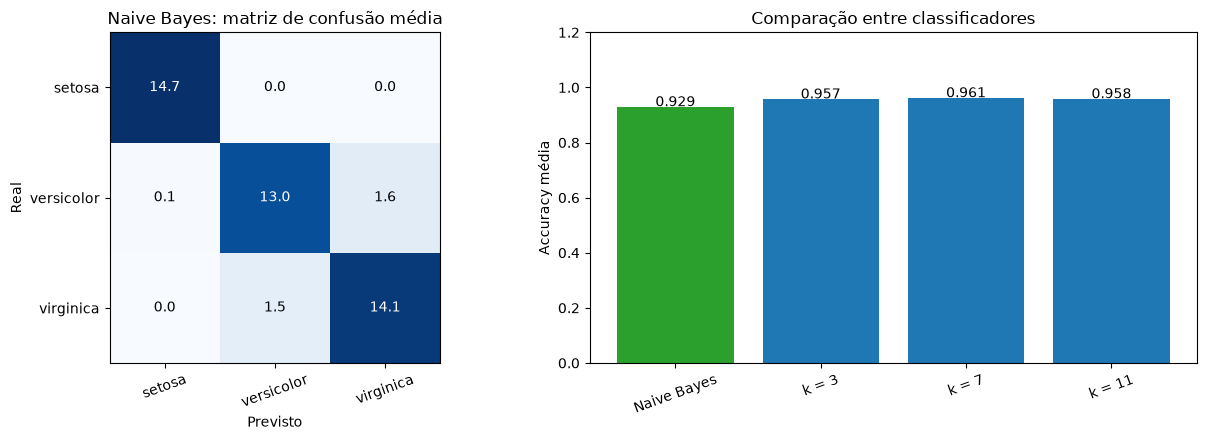

In [30]:
# Visualizações do Exercício 3

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].imshow(nb_confusion_mean, cmap="Blues")
for row_index in range(len(class_names_nb)):
    for column_index in range(len(class_names_nb)):
        axes[0].text(
            column_index,
            row_index,
            f"{nb_confusion_mean[row_index, column_index]:.1f}",
            ha="center",
            va="center",
            color="white"
            if nb_confusion_mean[row_index, column_index] > nb_confusion_mean.max() / 2
            else "black",
        )
axes[0].set_xticks(range(len(class_names_nb)), [name.replace("Iris-", "") for name in class_names_nb], rotation=20)
axes[0].set_yticks(range(len(class_names_nb)), [name.replace("Iris-", "") for name in class_names_nb])
axes[0].set_xlabel("Previsto")
axes[0].set_ylabel("Real")
axes[0].set_title("Naive Bayes: matriz de confusão média")

model_names = ["Naive Bayes", "k = 3", "k = 7", "k = 11"]
model_accuracies = [
    nb_metrics_mean[0],
    np.mean(accuracies[3]),
    np.mean(accuracies[7]),
    np.mean(accuracies[11]),
]
axes[1].bar(model_names, model_accuracies, color=["tab:green", "tab:blue", "tab:blue", "tab:blue"])
axes[1].set_ylim(0, 1.2)
axes[1].set_ylabel("Accuracy média")
axes[1].set_title("Comparação entre classificadores")
axes[1].tick_params(axis="x", rotation=20)
for index, value in enumerate(model_accuracies):
    axes[1].text(index, value + 0.003, f"{value:.3f}", ha="center")

plt.tight_layout()
plt.show()

## Exercise 4
Use the dataset from the previous exercise, with the categorized values (high, medium, low). Use Iris-setosa as your target value (p+ are the examples classified as Iris-setosa and p− the remaining ones) and create 3 new datasets by putting in each the examples that have the same values in the first column: the Low Dataset has all elements that have the value low in the first column, the Medium Dataset has all the examples that have the value medium, and the High Dataset has all the elements that have the value high.

#### 1. Calculate the entropy of the 4 datasets (the complete dataset and the three subsets).

Remember that a set’s ($S$) entropy is calculated by:

$$
\operatorname{entropy}(S) = -(p^+) \times \log_2(p^+) - (p^-) \times \log_2(p^-)
$$

Calculate the gain of the split of $S$ by feature $a$:

$$
\operatorname{gain}(S, a) = \operatorname{entropy}(S) -
\sum_v \left(\frac{|S_v|}{|S|} \times \operatorname{entropy}(S_v)\right)
$$

where $|S|$ is the number of elements in $S$ and $S_v$ is each of the subsets of $S$ when partitioned by the value of $a$.

In [31]:
ex4_thresholds = np.quantile(X_iris_raw, [1 / 3, 2 / 3], axis=0)
ex4_discrete = discretize_with_thresholds(X_iris_raw, ex4_thresholds)

ex4_positive = y_iris == class_names_nb[0]  # Iris-setosa
ex4_negative = ~ex4_positive
ex4_first_feature_categories = ex4_discrete[:, 0]


def ex4_entropy(positive_selection):
    total = len(positive_selection)
    if total == 0:
        return 0.0
    positive_probability = np.sum(positive_selection) / total
    negative_probability = 1 - positive_probability
    entropy_value = 0.0
    for probability in [positive_probability, negative_probability]:
        if probability > 0:
            entropy_value -= probability * np.log2(probability)
    return entropy_value


ex4_subsets = {
    "Completo": np.ones(len(y_iris), dtype=bool),
    "Low": ex4_first_feature_categories == 0,
    "Medium": ex4_first_feature_categories == 1,
    "High": ex4_first_feature_categories == 2,
}

ex4_entropy_rows = []
for subset_name, subset_selection in ex4_subsets.items():
    subset_positive = ex4_positive[subset_selection]
    ex4_entropy_rows.append([
        subset_name,
        int(subset_selection.sum()),
        int(subset_positive.sum()),
        int((~subset_positive).sum()),
        ex4_entropy(subset_positive),
    ])

ex4_entropy_table = pd.DataFrame(
    ex4_entropy_rows,
    columns=["Dataset", "Total", "p+", "p-", "Entropia"],
)
print(ex4_entropy_table.round(4).to_string(index=False))

 Dataset  Total  p+  p-  Entropia
Completo    150  50 100    0.9183
     Low     46  40   6    0.5586
  Medium     53  10  43    0.6987
    High     51   0  51    0.0000


O alvo é binário: **p+** corresponde a `Iris-setosa` e **p-** corresponde às restantes classes.

| Dataset | Total | p+ | p- | Entropia |
|---|---:|---:|---:|---:|
| Completo | 150 | 50 | 100 | 0.9183 |
| Low | 46 | 40 | 6 | 0.5586 |
| Medium | 53 | 10 | 43 | 0.6987 |
| High | 51 | 0 | 51 | 0.0000 |

As categorias têm tamanhos diferentes porque existem valores repetidos nos pontos de corte dos tercis. O subconjunto `High` é puro, enquanto os subconjuntos `Low` e `Medium` ainda misturam exemplos positivos e negativos.

#### 2- What is the value of gain(S,a) for the above split? What does it mean in terms of your ability to classify the elements of S before and after the split?

In [32]:
# Exercício 4.2 - Ganho da divisão pelo primeiro atributo

ex4_parent_entropy = ex4_entropy(ex4_positive)
ex4_weighted_child_entropy = sum(
    (subset_selection.sum() / len(y_iris))
    * ex4_entropy(ex4_positive[subset_selection])
    for subset_selection in ex4_subsets.values()
    if subset_selection is not ex4_subsets["Completo"]
)
ex4_gain_first_feature = ex4_parent_entropy - ex4_weighted_child_entropy

print(f"Entropia(S) = {ex4_parent_entropy:.4f}")
print(f"Entropia ponderada após a divisão = {ex4_weighted_child_entropy:.4f}")
print(f"gain(S, primeiro atributo) = {ex4_gain_first_feature:.4f}")

Entropia(S) = 0.9183
Entropia ponderada após a divisão = 0.4182
gain(S, primeiro atributo) = 0.5001


Para a divisão pelo primeiro atributo (`sepal_length`), a entropia do dataset original é `0.9183` e a entropia ponderada dos três subconjuntos é `0.4182`.

Assim:

$$
\operatorname{gain}(S, a_1) = 0.9183 - 0.4182 = 0.5001
$$

O ganho é positivo, portanto conhecer a categoria de `sepal_length` reduz a incerteza sobre a classe. No entanto, a divisão não é perfeita: os subconjuntos `Low` e `Medium` ainda contêm exemplos setosa e não setosa. O subconjunto `High` é puro.

#### 3- Do the same for all features of your dataset. Which is the feature with greatest gain?
How can you improve your chances of guessing a random examples’ class using this information?

In [33]:
# Exercício 4.3 - Ganho de informação de todas as features

ex4_feature_gains = []
for feature_index, feature_name in enumerate(feature_names):
    weighted_entropy = 0.0
    for category in range(3):
        category_selection = ex4_discrete[:, feature_index] == category
        weighted_entropy += (
            category_selection.sum() / len(y_iris)
        ) * ex4_entropy(ex4_positive[category_selection])
    gain_value = ex4_parent_entropy - weighted_entropy
    ex4_feature_gains.append([feature_name, gain_value])

ex4_gain_table = pd.DataFrame(
    ex4_feature_gains,
    columns=["Feature", "Ganho de informação"],
).sort_values("Ganho de informação", ascending=False)

print(ex4_gain_table.round(4).to_string(index=False))
print(
    f"\nMelhor feature: {ex4_gain_table.iloc[0]['Feature']} "
    f"(ganho = {ex4_gain_table.iloc[0]['Ganho de informação']:.4f})"
)

     Feature  Ganho de informação
 petal_width               0.9183
petal_length               0.9183
sepal_length               0.5001
 sepal_width               0.2777

Melhor feature: petal_width (ganho = 0.9183)


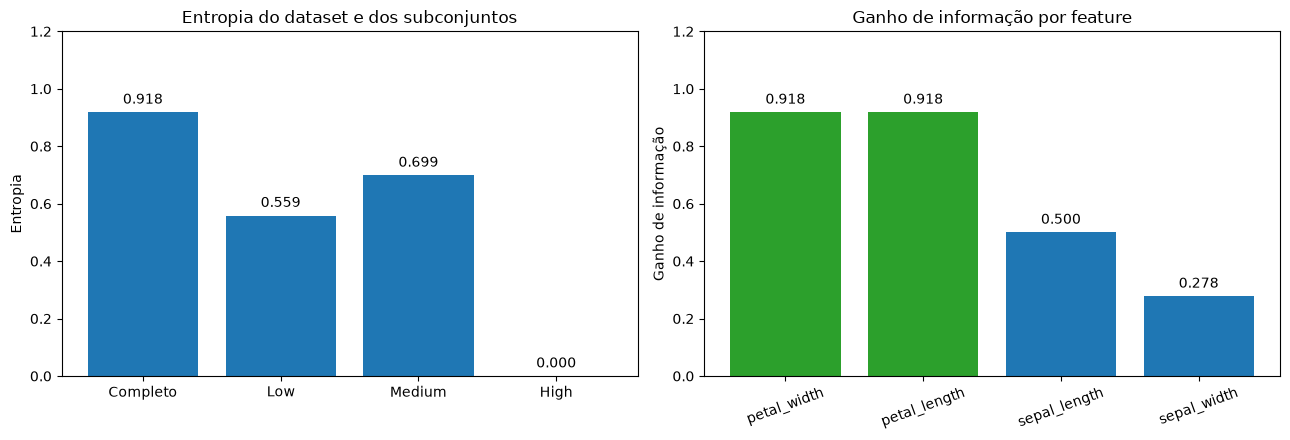

In [34]:
# Visualizações do Exercício 4

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

entropy_labels = ex4_entropy_table["Dataset"]
entropy_values = ex4_entropy_table["Entropia"]
axes[0].bar(entropy_labels, entropy_values, color=["tab:blue", "tab:blue", "tab:blue", "tab:blue"])
axes[0].set_ylabel("Entropia")
axes[0].set_title("Entropia do dataset e dos subconjuntos")
axes[0].set_ylim(0, 1.2)
for index, value in enumerate(entropy_values):
    axes[0].text(index, value + 0.03, f"{value:.3f}", ha="center")

feature_labels = ex4_gain_table["Feature"]
gain_values = ex4_gain_table["Ganho de informação"]
bar_colors = ["tab:green" if value == gain_values.max() else "tab:blue" for value in gain_values]
axes[1].bar(feature_labels, gain_values, color=bar_colors)
axes[1].set_ylabel("Ganho de informação")
axes[1].set_title("Ganho de informação por feature")
axes[1].set_ylim(0, 1.2)
axes[1].tick_params(axis="x", rotation=20)
for index, value in enumerate(gain_values):
    axes[1].text(index, value + 0.03, f"{value:.3f}", ha="center")

plt.tight_layout()
plt.show()

Os ganhos calculados para todas as features são:

| Feature | Ganho de informação |
|---|---:|
| `petal_width` | 0.9183 |
| `petal_length` | 0.9183 |
| `sepal_length` | 0.5001 |
| `sepal_width` | 0.2777 |

A célula imprime `petal_width` como a primeira feature, mas `petal_length` apresenta o mesmo ganho quando arredondado a quatro casas decimais. Portanto, ambas são as melhores candidatas para a raiz da árvore. Para aumentar a probabilidade de acertar a classe de um exemplo aleatório, devemos escolher uma destas features como primeiro teste. Nesta discretização, cada uma separa perfeitamente a setosa das restantes classes. Em caso de empate, qualquer uma pode ser escolhida, ou pode usar-se um critério adicional, como menor número de categorias ou validação num conjunto de teste.

#### 4- Explain how to build a decision tree with this information

Para construir uma árvore de decisão com esta informação:

1. Começamos no nó raiz com todos os 150 exemplos.
2. Calculamos o ganho de informação de cada feature disponível.
3. Escolhemos como raiz uma feature com maior ganho. Neste caso, `petal_length` e `petal_width` estão empatadas com `0.9183`.
4. Criamos um ramo para cada categoria da feature escolhida: `low`, `medium` e `high`.
5. Calculamos a distribuição das classes em cada ramo. Se um ramo for puro, transformamo-lo diretamente numa folha.
6. Se um ramo ainda tiver exemplos de classes diferentes, repetimos o processo usando apenas as features que ainda não foram usadas.
7. Paramos quando todos os exemplos de um ramo pertencem à mesma classe, quando não existem features disponíveis ou quando um critério de paragem for atingido.

Neste caso, uma árvore que escolha `petal_width` ou `petal_length` na raiz consegue separar a setosa das restantes classes com esta discretização. A classe `Iris-setosa` corresponde aos valores baixos destas features, enquanto os valores médios e altos correspondem às classes não setosa.

A escolha do maior ganho reduz a entropia o mais rapidamente possível. Em datasets reais, deve-se ainda avaliar a árvore em dados de teste e considerar limites de profundidade ou poda para evitar overfitting.